# SHAP-Guided SMOTE Benchmark: NSL-KDD Network Intrusion

**Research question.** Does using SHAP feature attributions *inside* the oversampler produce better synthetic
minority samples, and better minority-class classification, than conventional oversampling?

This notebook is one of four that run **the same experiment** on different datasets
(`01` Breast Cancer, `02` Credit Card Fraud, `03` Stroke, `04` NSL-KDD). All four are generated from one template
(`scripts/build_experiment_notebooks.py`) and import every algorithm from `src/`, so the only difference between
them is the dataset loaded in the first code cell. `05_cross_dataset_comparison.ipynb` compares the four.

| | Method | Type | How it creates minority samples |
|---|---|---|---|
| 0 | **No Sampling** | reference | none, trains on the imbalanced data |
| 1 | **Random Oversampling** | established | duplicates random minority rows |
| 2 | **SMOTE** | established (Chawla et al., 2002) | interpolates between a minority row and one of its k nearest minority neighbours (Euclidean) |
| 3 | **Borderline-SMOTE** | established (Han et al., 2005) | SMOTE, but only from minority rows near the class boundary (DANGER rows) |
| 4 | **SHAP-Filtered SMOTE** | **proposed** | SMOTE whose neighbours are searched only on the features that hold 90% of the SHAP importance |
| 5 | **SHAP-Weighted SMOTE** | **proposed** | SMOTE whose neighbour distance weights every feature by its SHAP importance: $d_W=\sqrt{\sum_j w_j (a_j-b_j)^2}$ |

**Stages:** 1 ingestion → 2 EDA → 3 leak-free preprocessing → 4 oversampling and synthetic-sample inspection →
5 repeated cross-validation → 6 hold-out test evaluation → 7 SHAP explainability comparison → 8 saved outputs,
summary and interpretation.

In [1]:
import sys, warnings
from pathlib import Path

# Locate the repository root (the folder that contains src/), wherever the notebook is run from
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "experiment").is_dir())
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.experiment import config as C
from src.experiment import data as D, preprocessing as P, runner as R, inspection as I
from src.experiment import plots as PL, outputs as O, summary as S

%matplotlib inline
PL.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATASET = "nsl_kdd"   # <- the only line that differs between the four dataset notebooks
DIRS = O.results_dirs(DATASET)
PLOTS = DIRS["plots"]
display(C.settings_table())

,Value
Setting,
Random seed,42
Hold-out test size,"25% (stratified, untouched)"
Cross-validation,2 x 5-fold stratified on the development set
Oversampling target,1:1 minority:majority (sampling_strategy='auto')
k neighbours (all SMOTE variants),5
Borderline-SMOTE m neighbours,10
SHAP-Filtered cumulative threshold,0.9000
SHAP preliminary model,"Random Forest, 50 trees, depth 5 (training fol..."
SHAP rows explained,"all rows up to 20,000; above that all minority..."


## Stage 1: Data ingestion
The loader drops identifier and non-feature columns, exact duplicate rows and constant columns, and records any
one-off subsampling that fixes the imbalance ratio. None of these steps learns anything from the data. The
DataFrame index is the **original row number in the source file**, so every synthetic sample can later be traced
back to two real records.

In [2]:
df, spec = D.load_dataset(DATASET)
display(pd.Series({"Source": spec.source, "URL": spec.url, "License": spec.license, "File": spec.file,
                   "Target": spec.target_definition}, name=spec.title).to_frame())
display(Markdown("**Dataset-level steps applied by the loader:**\n" + "\n".join(f"- {n}" for n in spec.notes)))
print(f"Shape after loading: {df.shape[0]:,} rows x {df.shape[1] - 1} features + target")
display(df.head())

,NSL-KDD Network Intrusion (KDDTrain+)
Source,"Canadian Institute for Cybersecurity, UNB (Tav..."
URL,https://www.unb.ca/cic/datasets/nsl.html
License,Free for research use (CIC/UNB); Kaggle mirror...
File,data/nsl_kdd/KDDTrain+.txt
Target,label != 'normal' (any attack) -> 1


**Dataset-level steps applied by the loader:**
- `difficulty` dropped: the NSL-KDD authors' count of how many reference classifiers got the record right, which is metadata, not a network feature.
- `label` (attack name) dropped after deriving the binary target.
- Dropped 9 exact duplicate rows (features + target).
- Dropped constant column(s): num_outbound_cmds.
- Attack records subsampled once (seed 42) from 58,621 to 5,856 so attacks are 8% of the data (about 11.5:1); the natural split is close to balanced (47% attacks). All normal records are kept.

Shape after loading: 73,199 rows x 40 features + target


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,is_host_login,...,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,target
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,2,2,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,150,25,0.1700,0.0300,0.1700,0.0000,0.0000,0.0000,0.0500,0.0000,0
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,13,1,0.0000,0.0000,0.0000,0.0000,0.0800,0.1500,0.0000,255,1,0.0000,0.6000,0.8800,0.0000,0.0000,0.0000,0.0000,0.0000,0
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,123,6,1.0000,1.0000,0.0000,0.0000,0.0500,0.0700,0.0000,255,26,0.1000,0.0500,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,...,5,5,0.2000,0.2000,0.0000,0.0000,1.0000,0.0000,0.0000,30,255,1.0000,0.0000,0.0300,0.0400,0.0300,0.0100,0.0000,0.0100,0
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,...,30,32,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0900,255,255,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0


In [3]:
quality = D.quality_report(df, spec)
print(f"Numerical features ({len(spec.numeric_features)}): {', '.join(spec.numeric_features[:12])}"
      + (" ..." if len(spec.numeric_features) > 12 else ""))
print(f"Categorical features ({len(spec.categorical_features)}): {', '.join(spec.categorical_features) or 'none'}")
display(D.quality_summary(df, spec))
display(quality.sort_values("Missing", ascending=False).head(12))

Numerical features (37): duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted ...
Categorical features (3): protocol_type, service, flag


,Count,Handling
Check,,
Missing cells,0,Median / most-frequent imputation fitted on ea...
Infinite cells,0,Would be set to missing
Duplicate rows remaining,0,Exact duplicates already dropped at load time
Rows with |z| > 5 on any numeric feature,4941,Flagged only: in imbalanced problems extreme r...
Categorical features,3,One-hot encoded inside each training fold


,Type,dtype,Missing,Unique,Min,Max,Binary 0/1
Feature,,,,,,,
duration,numeric,int64,0,2032,0.0000,"42,837.0000",False
src_bytes,numeric,int64,0,3289,0.0000,"1,379,963,888.0000",False
dst_bytes,numeric,int64,0,9284,0.0000,"7,028,652.0000",False
land,numeric,int64,0,2,0.0000,1.0000,True
wrong_fragment,numeric,int64,0,3,0.0000,3.0000,False
urgent,numeric,int64,0,4,0.0000,3.0000,False
hot,numeric,int64,0,28,0.0000,77.0000,False
num_failed_logins,numeric,int64,0,5,0.0000,4.0000,False
logged_in,numeric,int64,0,2,0.0000,1.0000,True


## Stage 2: Exploratory data analysis
EDA is descriptive only. The Kolmogorov-Smirnov ranking below only chooses which features to plot; it is never
used by any model or oversampler.

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
NSL-KDD Network Intrusion (KDDTrain+),Network security,73199,37,3,67343,5856,8.00%,11.5 : 1,1 : 11.5


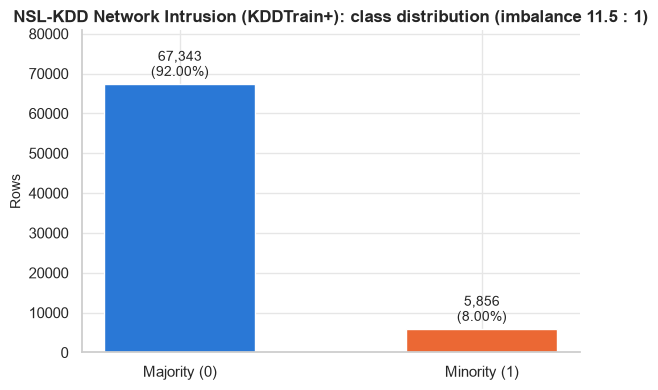

In [4]:
display(D.overview(df, spec))
PL.class_distribution(df, spec.title, PLOTS); plt.show()

,KS D (majority vs minority)
src_bytes,0.8418
dst_bytes,0.8100
same_srv_rate,0.7188
diff_srv_rate,0.7181
dst_host_srv_count,0.7098
dst_host_same_srv_rate,0.7051
logged_in,0.6765
dst_host_diff_srv_rate,0.6578
count,0.6429
dst_host_serror_rate,0.6110


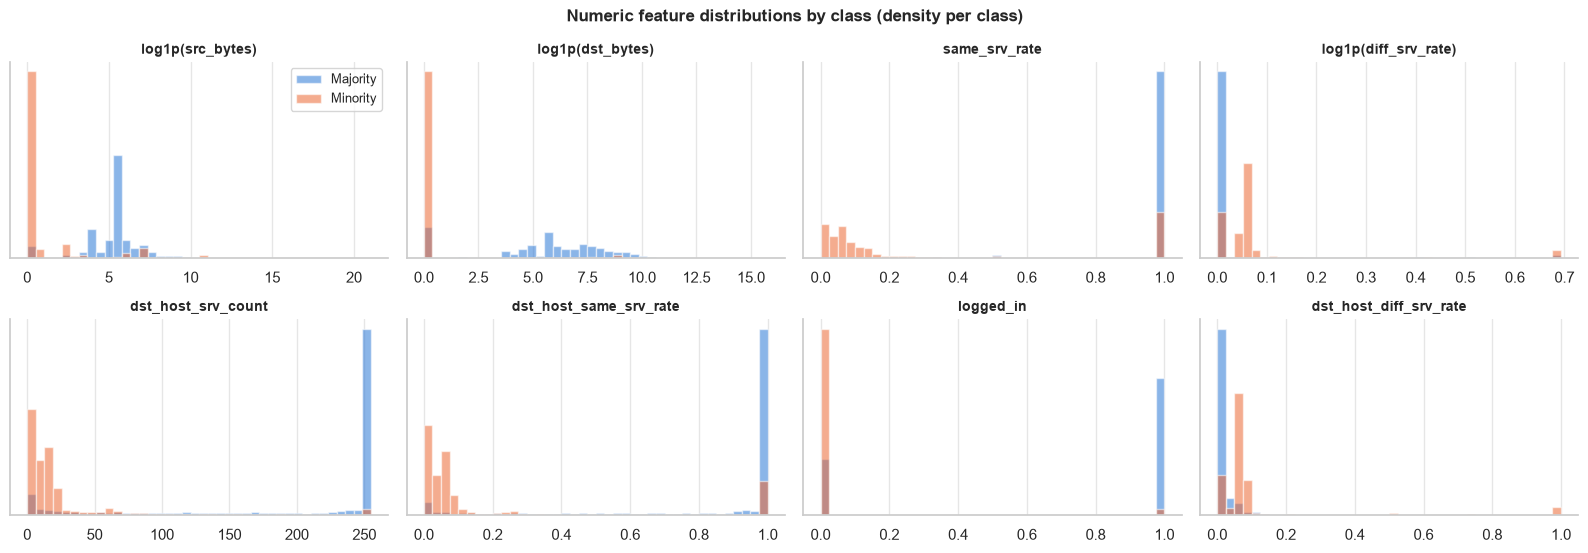

In [5]:
ks = D.ks_ranking(df, spec)
display(ks.head(10).to_frame("KS D (majority vs minority)"))
TOP_KS = list(ks.index[:8])
PL.feature_distributions(df, TOP_KS, PLOTS); plt.show()

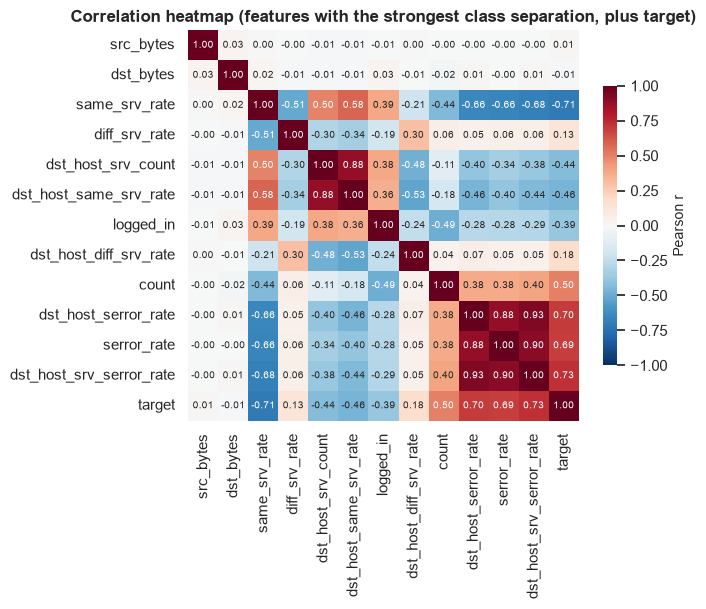

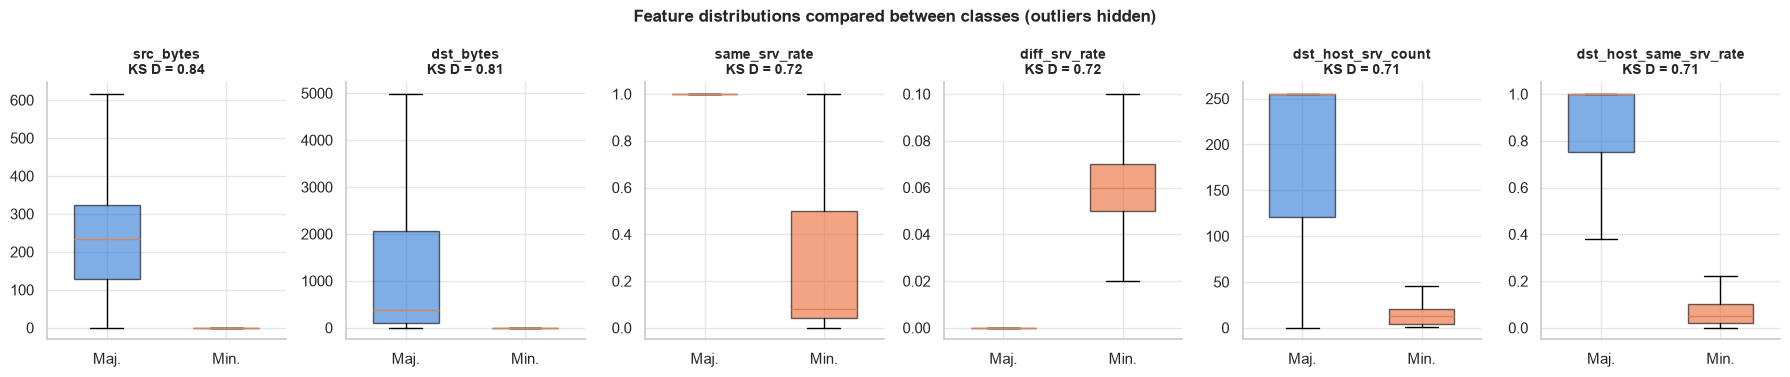

In [6]:
PL.correlation_heatmap(df, list(ks.index[:12]), PLOTS); plt.show()
PL.class_comparison(df, TOP_KS[:6], ks, PLOTS); plt.show()

## Stage 3: Leak-free preprocessing
```
full data --stratified 25%--> TEST (never resampled; used once, in Stage 6)
   └── DEVELOPMENT (75%) ── repeated stratified k-fold (Stage 5); in each fold, on the training part only:
                            impute + encode + scale  →  SHAP (inside the SHAP samplers)  →  oversample  →  fit model
```
Missing values: median (numeric) / most frequent (categorical) imputation. Categorical features are one-hot
encoded and numeric features are standardised. Every one of these steps is fitted on training rows only. The
table below shows the final fit on the whole development set: the scaler makes the development data exactly
mean 0, while the test set is only *close* to 0, because the test set was never used to fit anything.

In [7]:
dev_df, test_df = P.split_dev_test(df)
split = pd.DataFrame({"Rows": [len(dev_df), len(test_df)],
                      "Majority (0)": [int((dev_df.target == 0).sum()), int((test_df.target == 0).sum())],
                      "Minority (1)": [int(dev_df.target.sum()), int(test_df.target.sum())]},
                     index=["Development (75%)", "Hold-out test (25%)"])
split["Minority %"] = (split["Minority (1)"] / split["Rows"]).map("{:.2%}".format)
display(split)
assert not set(dev_df.index) & set(test_df.index), "development and test rows overlap"

pre = P.Preprocessor(spec).fit(dev_df)
print(f"Model space after encoding: {len(pre.feature_names_)} columns "
      f"({pre.n_numeric_} scaled numeric + {len(pre.feature_names_) - pre.n_numeric_} one-hot)")
display(pre.summary(dev_df, test_df).head(15))

,Rows,Majority (0),Minority (1),Minority %
Development (75%),54899,50507,4392,8.00%
Hold-out test (25%),18300,16836,1464,8.00%


Model space after encoding: 116 columns (37 scaled numeric + 79 one-hot)


,Kind,Missing (train),Imputation value (train median),Scaler mean (train),Scaler std (train),Train mean after,Test mean after
Feature,,,,,,,
duration,numeric,0,0.0000,188.2693,"1,589.8102",-0.0000,0.0062
src_bytes,numeric,0,225.0000,"40,946.0549","5,967,355.4549",0.0000,-0.0045
dst_bytes,numeric,0,334.0000,"3,918.9981","60,709.0644",-0.0000,0.0097
land,numeric,0,0.0000,0.0002,0.0128,0.0000,-0.0128
wrong_fragment,numeric,0,0.0000,0.0037,0.1021,-0.0000,0.0139
urgent,numeric,0,0.0000,0.0002,0.0186,0.0000,-0.0059
hot,numeric,0,0.0000,0.2106,2.1824,0.0000,0.0247
num_failed_logins,numeric,0,0.0000,0.0012,0.0409,0.0000,0.0147
logged_in,numeric,0,1.0000,0.6556,0.4752,0.0000,0.0081


## Stage 4: Oversampling and synthetic-sample inspection
The cell below fits **every sampler on the preprocessed development set** (the same chain is re-run inside every
CV fold in Stage 5) and fits the three downstream models on each resampled set. Test-set scores are only reported
in Stage 6.

All SMOTE-family methods share one generation engine (`src/oversampling/provenance.py`):
$x_{new} = x_a + \lambda (x_{nn} - x_a)$ with $\lambda \sim U(0,1)$, interpolated in the full, unweighted feature space.
They differ only in **which rows can be anchors** $x_a$ and **in which space the neighbour $x_{nn}$ is searched**.
They also share one random seed. For SMOTE, SHAP-Filtered SMOTE and SHAP-Weighted SMOTE (which all draw anchors
from every minority row), synthetic row *i* therefore has the same anchor, the same neighbour rank and the same
$\lambda$, so any difference between these three comes from neighbour selection alone. Borderline-SMOTE draws
from a smaller anchor pool, so its rows pair up differently. The engine records the parents, neighbour rank,
distance and $\lambda$ of every synthetic row.

No Sampling            sampled in    0.0 s, 3 models fitted and scored on the test set


Random Oversampling    sampled in    1.4 s, 3 models fitted and scored on the test set


SMOTE                  sampled in    2.7 s, 3 models fitted and scored on the test set


Borderline-SMOTE       sampled in    4.0 s, 3 models fitted and scored on the test set


SHAP-Filtered SMOTE    sampled in   21.9 s, 3 models fitted and scored on the test set


SHAP-Weighted SMOTE    sampled in   15.7 s, 3 models fitted and scored on the test set


,Anchor pool,Neighbour search space,Features in search,Search features (first 8),Synthetic rows
Method,,,,,
No Sampling,-,-,0,-,0
Random Oversampling,all minority rows,none (exact copies),0,-,46115
SMOTE,all minority rows,all features (Euclidean),116,"duration, src_bytes, dst_bytes, land, wrong_fr...",46115
Borderline-SMOTE,DANGER rows only (86 of 4392),all features (Euclidean),116,"duration, src_bytes, dst_bytes, land, wrong_fr...",46115
SHAP-Filtered SMOTE,all minority rows,23 SHAP-selected features (Euclidean),23,"src_bytes, dst_bytes, logged_in, count, srv_co...",46115
SHAP-Weighted SMOTE,all minority rows,"all features, column j scaled by sqrt(w_j)",116,"duration, src_bytes, dst_bytes, land, wrong_fr...",46115


,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds
method,,,,,,
No Sampling,50507,4392,0,50507,4392,0.0440
Random Oversampling,50507,4392,46115,50507,50507,1.4074
SMOTE,50507,4392,46115,50507,50507,2.6975
Borderline-SMOTE,50507,4392,46115,50507,50507,4.0282
SHAP-Filtered SMOTE,50507,4392,46115,50507,50507,21.9148
SHAP-Weighted SMOTE,50507,4392,46115,50507,50507,15.6802


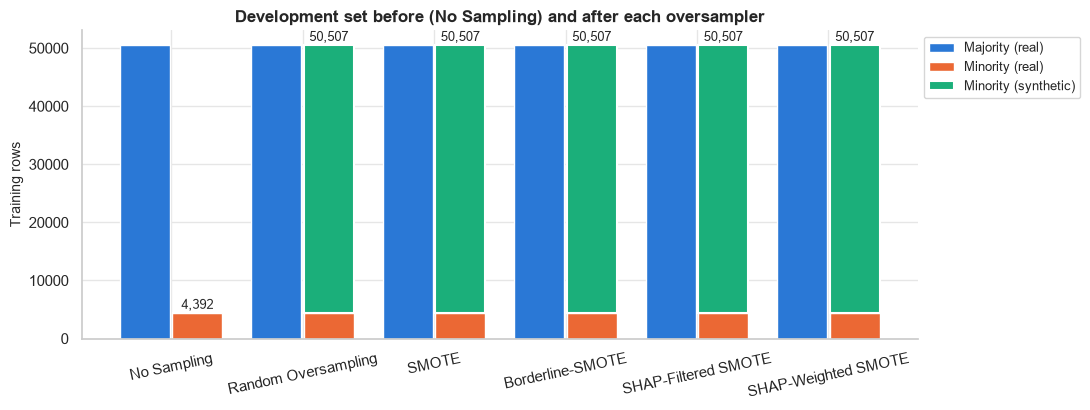

In [8]:
final = R.run_final(dev_df, test_df, spec)
display(I.search_space_description(final))
display(final.sampling)
PL.balanced_class_counts(final, PLOTS); plt.show()

### 4A. Neighbour identification
For each method: the k = 5 nearest minority neighbours of the first two minority seeds, the distance in the
method's search space, the plain Euclidean distance, the rank the same neighbour would have under plain SMOTE,
and the features that make up most of the search distance. For Borderline-SMOTE each seed is also labelled
SAFE / DANGER / NOISE from its 10 nearest neighbours in the whole training set; only DANGER rows can be anchors.

In [9]:
seed_ids = final.dev_row_ids[final.samplers["SMOTE"].minority_positions_[:2]]
for m in I.INTERPOLATING:
    t = I.neighbour_table(final, m, max_seeds=2)
    display(Markdown(f"**{m}**"))
    display(t.drop(columns="method"))
bl = final.samplers["Borderline-SMOTE"]
display(pd.Series({"SAFE": int(bl.safe_mask_.sum()), "DANGER (anchors)": int(bl.danger_mask_.sum()),
                   "NOISE": int(bl.noise_mask_.sum())}, name="Borderline-SMOTE seed status").to_frame())
display(I.neighbour_overlap_with_smote(final))

**SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,93412,1,39766,0.2387,0.2387,1,"count (48%), dst_host_count (17%), same_srv_ra..."
1,93412,2,106571,0.4756,0.4756,2,"count (27%), same_srv_rate (25%), dst_host_sam..."
2,93412,3,95775,0.5421,0.5421,3,"count (51%), dst_host_same_srv_rate (21%), dst..."
3,93412,4,76782,0.5633,0.5633,4,"dst_host_count (37%), dst_host_same_srv_rate (..."
4,93412,5,56458,0.5684,0.5684,5,"dst_host_count (34%), dst_host_same_srv_rate (..."
5,11975,1,89780,0.3148,0.3148,1,"srv_count (37%), same_srv_rate (25%), dst_host..."
6,11975,2,104094,0.3246,0.3246,2,"srv_count (35%), same_srv_rate (24%), dst_host..."
7,11975,3,33234,0.3696,0.3696,3,"count (87%), dst_host_diff_srv_rate (4%), diff..."
8,11975,4,3526,0.3896,0.3896,4,"count (85%), srv_count (4%), dst_host_diff_srv..."
9,11975,5,78924,0.4561,0.4561,5,"count (94%), same_srv_rate (3%), dst_host_same..."


**Borderline-SMOTE**

,seed_row_id,seed_status,majority_in_10_nn,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,93412,SAFE,0,1,39766,0.2387,0.2387,1,"count (48%), dst_host_count (17%), same_srv_ra..."
1,93412,SAFE,0,2,106571,0.4756,0.4756,2,"count (27%), same_srv_rate (25%), dst_host_sam..."
2,93412,SAFE,0,3,95775,0.5421,0.5421,3,"count (51%), dst_host_same_srv_rate (21%), dst..."
3,93412,SAFE,0,4,76782,0.5633,0.5633,4,"dst_host_count (37%), dst_host_same_srv_rate (..."
4,93412,SAFE,0,5,56458,0.5684,0.5684,5,"dst_host_count (34%), dst_host_same_srv_rate (..."
5,11975,SAFE,0,1,89780,0.3148,0.3148,1,"srv_count (37%), same_srv_rate (25%), dst_host..."
6,11975,SAFE,0,2,104094,0.3246,0.3246,2,"srv_count (35%), same_srv_rate (24%), dst_host..."
7,11975,SAFE,0,3,33234,0.3696,0.3696,3,"count (87%), dst_host_diff_srv_rate (4%), diff..."
8,11975,SAFE,0,4,3526,0.3896,0.3896,4,"count (85%), srv_count (4%), dst_host_diff_srv..."
9,11975,SAFE,0,5,78924,0.4561,0.4561,5,"count (94%), same_srv_rate (3%), dst_host_same..."


**SHAP-Filtered SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,93412,1,39766,0.2177,0.2387,1,"count (58%), same_srv_rate (13%), dst_host_dif..."
1,93412,2,49839,0.2898,1.6030,60,"dst_host_srv_count (34%), dst_host_same_srv_ra..."
2,93412,3,91215,0.3590,0.6231,8,"dst_host_same_srv_rate (47%), dst_host_diff_sr..."
3,93412,4,20920,0.3662,0.6594,11,"dst_host_diff_srv_rate (59%), count (24%), dst..."
4,93412,5,19598,0.3698,1.3445,41,"dst_host_same_srv_rate (79%), same_srv_rate (1..."
5,11975,1,113702,0.0234,1.4144,8,"srv_count (47%), count (35%), dst_host_srv_cou..."
6,11975,2,77900,0.0335,1.4146,9,"count (68%), srv_count (23%), dst_host_srv_cou..."
7,11975,3,125327,0.0455,1.4149,10,"count (83%), srv_count (12%), dst_host_srv_cou..."
8,11975,4,11221,0.0627,2.0010,246,"same_srv_rate (40%), srv_count (26%), dst_host..."
9,11975,5,3395,0.0627,2.0010,246,"same_srv_rate (40%), srv_count (26%), dst_host..."


**SHAP-Weighted SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,93412,1,39766,0.0413,0.2387,1,"count (53%), same_srv_rate (21%), dst_host_dif..."
1,93412,2,91215,0.0844,0.6231,8,"dst_host_count (45%), dst_host_same_srv_rate (..."
2,93412,3,20920,0.0856,0.6594,11,"dst_host_count (51%), dst_host_diff_srv_rate (..."
3,93412,4,106571,0.0884,0.4756,2,"same_srv_rate (41%), count (26%), dst_host_sam..."
4,93412,5,76782,0.0917,0.5633,4,"dst_host_same_srv_rate (36%), count (24%), dst..."
5,11975,1,113702,0.0068,1.4144,8,"service=domain (73%), count (14%), srv_count (8%)"
6,11975,2,77900,0.0088,1.4146,9,"service=domain (44%), count (32%), service=ctf..."
7,11975,3,125327,0.0098,1.4149,10,"count (58%), service=domain (35%), srv_count (4%)"
8,11975,4,60421,0.0145,1.4158,11,"same_srv_rate (42%), count (27%), service=doma..."
9,11975,5,24377,0.0155,1.4171,12,"dst_host_diff_srv_rate (51%), count (24%), ser..."


,Borderline-SMOTE seed status
SAFE,4273
DANGER (anchors),86
NOISE,33


,mean_jaccard_with_SMOTE_neighbours,seeds_with_identical_neighbours
method,,
SMOTE,1.0000,1.0000
Borderline-SMOTE,1.0000,1.0000
SHAP-Filtered SMOTE,0.5114,0.3855
SHAP-Weighted SMOTE,0.4993,0.2832


### 4B. Synthetic sample generation
Below are the first synthetic records of each method, with their two parents (original row ids), $\lambda$ and
neighbour rank, followed by a feature-by-feature walk through synthetic row #0 of every interpolating method.
Because of the shared seed, row #0 of SMOTE, SHAP-Filtered and SHAP-Weighted SMOTE has the same anchor and the
same $\lambda$, so you can see how the choice of neighbour changes the result (Borderline-SMOTE's anchor comes
from its DANGER pool). A Random Oversampling record is an exact copy of parent 1.

In [10]:
for m in C.OVERSAMPLERS:
    rec = I.generation_records(final, m)
    display(Markdown(f"**{m}**: {len(rec):,} synthetic rows"))
    display(rec.head(4).iloc[:, :14])

**Random Oversampling**: 46,115 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
0,1-0,Random Oversampling,113888,NaN,NaN,NaN,NaN,1,0.0000,8.0000,0.0000,0.0000,-0.0000,0.0000
1,1-1,Random Oversampling,99409,NaN,NaN,NaN,NaN,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000
2,1-2,Random Oversampling,72830,NaN,NaN,NaN,NaN,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000
3,1-3,Random Oversampling,77484,NaN,NaN,NaN,NaN,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000


**SMOTE**: 46,115 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
0,2-0,SMOTE,59752,"77,608.0000",4,0.4389,78.6856,1,0.0000,7.8998,0.0000,0.5611,-0.0000,0.0000
1,2-1,SMOTE,102704,"93,133.0000",5,0.6974,3.2992,1,0.0000,8.0000,0.0000,0.0000,-0.0000,0.0000
2,2-2,SMOTE,75646,"20,889.0000",1,0.9756,0.1357,1,0.0000,334.0000,0.0000,0.0000,-0.0000,0.0000
3,2-3,SMOTE,32694,"24,538.0000",4,0.7861,0.5012,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000


**Borderline-SMOTE**: 46,115 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
0,3-0,Borderline-SMOTE,46222,"35,897.0000",4,0.4389,1.7549,1,0.0000,"54,540.0000","8,314.0000",0.0000,-0.0000,0.0000
1,3-1,Borderline-SMOTE,114783,"111,847.0000",5,0.6974,5.6707,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000
2,3-2,Borderline-SMOTE,54901,"83,570.0000",1,0.9756,0.9624,1,0.0000,"54,540.0000","8,314.0000",0.0000,-0.0000,0.0000
3,3-3,Borderline-SMOTE,3785,"10,632.0000",4,0.7861,3.8914,1,0.0000,5.0648,0.0000,0.0000,-0.0000,0.0000


**SHAP-Filtered SMOTE**: 46,115 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
0,4-0,SHAP-Filtered SMOTE,59752,"39,773.0000",4,0.4389,8.5959,1,0.0000,7.8998,0.0000,0.5611,-0.0000,0.0000
1,4-1,SHAP-Filtered SMOTE,102704,"115,489.0000",5,0.6974,0.3683,1,0.0000,14.9737,0.0000,0.0000,-0.0000,0.0000
2,4-2,SHAP-Filtered SMOTE,75646,"20,889.0000",1,0.9756,0.1357,1,0.0000,334.0000,0.0000,0.0000,-0.0000,0.0000
3,4-3,SHAP-Filtered SMOTE,32694,"62,056.0000",4,0.7861,0.1108,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000


**SHAP-Weighted SMOTE**: 46,115 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
0,5-0,SHAP-Weighted SMOTE,59752,"81,192.0000",4,0.4389,2.0372,1,0.0000,0.0000,0.0000,0.5611,-0.0000,0.0000
1,5-1,SHAP-Weighted SMOTE,102704,"115,489.0000",5,0.6974,0.2211,1,0.0000,14.9737,0.0000,0.0000,-0.0000,0.0000
2,5-2,SHAP-Weighted SMOTE,75646,"20,889.0000",1,0.9756,0.0182,1,0.0000,334.0000,0.0000,0.0000,-0.0000,0.0000
3,5-3,SHAP-Weighted SMOTE,32694,"95,365.0000",4,0.7861,0.0257,1,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000


In [11]:
for m in I.INTERPOLATING:
    if final.samplers[m].n_synthetic_ == 0:
        continue
    ex = I.example_walkthrough(final, m, 0, max_features=8)
    display(Markdown(f"**{ex.attrs['header']}**"))
    display(ex)

**SMOTE: synthetic #0 = parent_1 (row 59752) + 0.4389 x (parent_2 (row 77608) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
duration,0.0000,0.0000,0.0000,0.0000,0.0000
src_bytes,0.0000,18.0000,18.0000,7.8998,7.8998
dst_bytes,0.0000,0.0000,0.0000,0.0000,0.0000
land,1.0000,0.0000,-1.0000,-0.4389,0.5611
wrong_fragment,-0.0000,-0.0000,0.0000,0.0000,-0.0000
urgent,0.0000,0.0000,0.0000,0.0000,0.0000
hot,0.0000,0.0000,0.0000,0.0000,0.0000
num_failed_logins,0.0000,0.0000,0.0000,0.0000,0.0000


**Borderline-SMOTE: synthetic #0 = parent_1 (row 46222) + 0.4389 x (parent_2 (row 35897) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
duration,0.0000,0.0000,0.0000,0.0000,0.0000
src_bytes,"54,540.0000","54,540.0000",0.0000,0.0000,"54,540.0000"
dst_bytes,"8,314.0000","8,314.0000",0.0000,0.0000,"8,314.0000"
land,0.0000,0.0000,0.0000,0.0000,0.0000
wrong_fragment,-0.0000,-0.0000,0.0000,0.0000,-0.0000
urgent,0.0000,0.0000,0.0000,0.0000,0.0000
hot,2.0000,2.0000,0.0000,0.0000,2.0000
num_failed_logins,0.0000,0.0000,0.0000,0.0000,0.0000


**SHAP-Filtered SMOTE: synthetic #0 = parent_1 (row 59752) + 0.4389 x (parent_2 (row 39773) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
flag,S0,SF,NaN,NaN,S0,0.1143
src_bytes,0.0000,18.0000,18.0000,7.8998,7.8998,0.0987
diff_srv_rate,0.0000,0.0000,0.0000,0.0000,0.0000,0.0850
service,finger,eco_i,NaN,NaN,finger,0.0731
dst_host_serror_rate,1.0000,-0.0000,-1.0000,-0.4389,0.5611,0.0607
same_srv_rate,1.0000,1.0000,0.0000,0.0000,1.0000,0.0572
dst_host_srv_serror_rate,0.7500,0.0000,-0.7500,-0.3292,0.4208,0.0560
srv_serror_rate,1.0000,0.0000,-1.0000,-0.4389,0.5611,0.0553


**SHAP-Weighted SMOTE: synthetic #0 = parent_1 (row 59752) + 0.4389 x (parent_2 (row 81192) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
flag,S0,S0,NaN,NaN,S0,0.1143
src_bytes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0987
diff_srv_rate,0.0000,0.0000,0.0000,0.0000,0.0000,0.0850
service,finger,finger,NaN,NaN,finger,0.0731
dst_host_serror_rate,1.0000,1.0000,0.0000,0.0000,1.0000,0.0607
same_srv_rate,1.0000,1.0000,0.0000,0.0000,1.0000,0.0572
dst_host_srv_serror_rate,0.7500,0.6500,-0.1000,-0.0439,0.7061,0.0560
srv_serror_rate,1.0000,1.0000,0.0000,0.0000,1.0000,0.0553


### 4C. SHAP guidance
Both proposed methods first fit a preliminary Random Forest (50 trees, depth 5) **on the training data only**,
explain it with `shap.TreeExplainer`, and turn the mean absolute SHAP value of each feature (MASV) into a weight
$w_j = \text{MASV}_j / \sum_k \text{MASV}_k$.
* **SHAP-Filtered SMOTE** searches neighbours only on the top features whose cumulative weight reaches 90%.
* **SHAP-Weighted SMOTE** multiplies every column by $\sqrt{w_j}$ before the Euclidean search, so the distance becomes
  $d_W(a,b)=\sqrt{\sum_j w_j (a_j-b_j)^2}$: high-SHAP features decide who counts as a neighbour.

The rationale tables show, for the first synthetic rows, the neighbour's rank in SHAP space and under plain SMOTE,
which features made up the SHAP distance, and how similar the two parents' SHAP explanations are (cosine).

,rank,MASV,weight_w,cumulative_weight,sqrt_w_stretch_vs_uniform,kept_by_SHAP_Filtered
src_bytes,1,0.0164,0.0987,0.0987,3.3843,True
diff_srv_rate,2,0.0141,0.0850,0.1838,3.1410,True
dst_host_serror_rate,3,0.0101,0.0607,0.2445,2.6541,True
same_srv_rate,4,0.0095,0.0572,0.3017,2.5749,True
dst_host_srv_serror_rate,5,0.0093,0.0560,0.3577,2.5486,True
srv_serror_rate,6,0.0092,0.0553,0.4130,2.5335,True
flag=SF,7,0.0090,0.0544,0.4674,2.5119,True
flag=S0,8,0.0089,0.0533,0.5207,2.4871,True
dst_bytes,9,0.0085,0.0512,0.5719,2.4371,True
logged_in,10,0.0074,0.0445,0.6165,2.2733,True


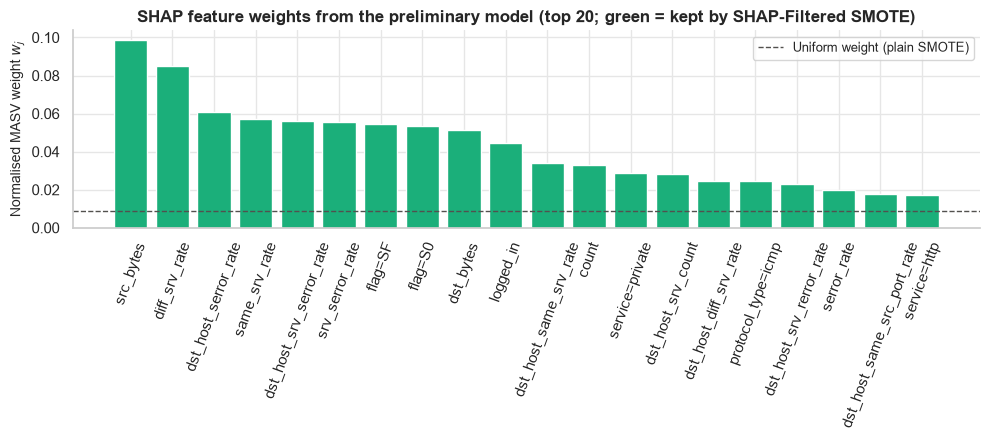

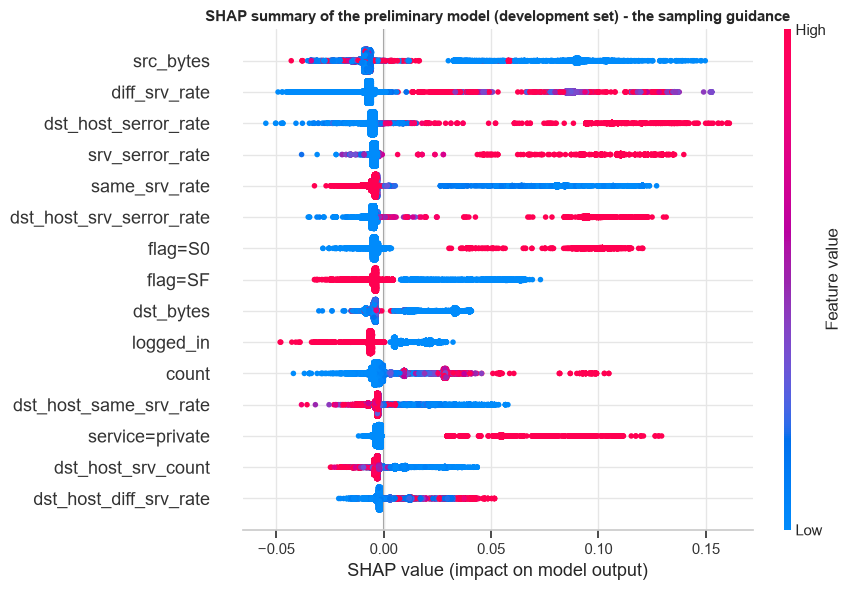

In [12]:
weights = I.shap_weight_table(final)
display(weights.head(15))
PL.masv_weights(weights, PLOTS); plt.show()
PL.shap_summary(final, PLOTS); plt.show()

In [13]:
for m in C.PROPOSED_METHODS:
    r = I.shap_rationale(final, m, n=8)
    display(Markdown(f"**{m}: neighbour-selection rationale (first 8 synthetic rows)**"))
    display(r)
    moved = (~r["would_plain_SMOTE_consider_it"]).mean()
    print(f"{moved:.0%} of these parent pairs would NOT be neighbours under plain SMOTE")
display(Markdown("**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**"))
display(I.parent_shap_detail(final, "SHAP-Weighted SMOTE", 0))

**SHAP-Filtered SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [src_bytes],SHAP p1/p2 [diff_srv_rate],SHAP p1/p2 [dst_host_serror_rate],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,59752,39773,0.4389,4,6,0.0900,"srv_serror_rate (27%), dst_host_serror_rate (2...",+0.049 / +0.011,-0.044 / -0.002,+0.076 / -0.005,False
1,102704,115489,0.6974,5,86,0.5570,"srv_count (91%), dst_host_srv_count (9%), src_...",+0.084 / +0.006,-0.001 / -0.006,-0.005 / -0.005,False
2,75646,20889,0.9756,1,1,1.0000,"dst_host_srv_diff_host_rate (91%), dst_host_sr...",-0.012 / -0.012,-0.006 / -0.006,-0.005 / -0.005,True
3,32694,62056,0.7861,4,10,0.9960,"dst_host_diff_srv_rate (40%), diff_srv_rate (3...",+0.091 / +0.087,+0.086 / +0.086,+0.106 / +0.108,False
4,77772,43480,0.4504,1,2,0.9830,"dst_host_srv_count (72%), dst_host_srv_rerror_...",+0.059 / +0.058,-0.005 / -0.005,-0.004 / -0.004,True
5,125796,53570,0.9268,2,21,1.0000,"dst_host_same_srv_rate (58%), srv_count (20%),...",+0.090 / +0.090,+0.087 / +0.087,+0.106 / +0.106,False
6,57003,37736,0.8228,4,4,1.0000,"count (51%), same_srv_rate (39%), diff_srv_rat...",+0.081 / +0.081,+0.089 / +0.089,+0.137 / +0.137,True
7,48601,53704,0.2272,3,3,1.0000,"same_srv_rate (50%), diff_srv_rate (34%), srv_...",+0.091 / +0.091,+0.090 / +0.090,+0.109 / +0.109,True


50% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [src_bytes],SHAP p1/p2 [diff_srv_rate],SHAP p1/p2 [dst_host_serror_rate],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,59752,81192,0.4389,4,214,0.8560,"dst_host_srv_diff_host_rate (54%), land (35%),...",+0.049 / +0.066,-0.044 / -0.044,+0.076 / +0.138,False
1,102704,115489,0.6974,5,86,0.5570,"srv_diff_host_rate (58%), service=eco_i (21%),...",+0.084 / +0.006,-0.001 / -0.006,-0.005 / -0.005,False
2,75646,20889,0.9756,1,1,1.0000,"dst_host_srv_diff_host_rate (86%), dst_host_sr...",-0.012 / -0.012,-0.006 / -0.006,-0.005 / -0.005,True
3,32694,95365,0.7861,4,9,0.9980,"diff_srv_rate (55%), dst_host_diff_srv_rate (1...",+0.091 / +0.091,+0.086 / +0.086,+0.106 / +0.106,False
4,77772,43480,0.4504,1,2,0.9830,"dst_host_srv_count (53%), dst_host_count (22%)...",+0.059 / +0.058,-0.005 / -0.005,-0.004 / -0.004,True
5,125796,105220,0.9268,2,25,1.0000,"same_srv_rate (50%), srv_count (18%), dst_host...",+0.090 / +0.090,+0.087 / +0.087,+0.106 / +0.106,False
6,57003,37736,0.8228,4,4,1.0000,"same_srv_rate (49%), count (36%), diff_srv_rat...",+0.081 / +0.081,+0.089 / +0.089,+0.137 / +0.137,True
7,48601,87766,0.2272,3,2,1.0000,"diff_srv_rate (67%), same_srv_rate (17%), dst_...",+0.091 / +0.091,+0.090 / +0.090,+0.109 / +0.109,True


50% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**

,SHAP weight w_j,in search space,share of search distance,SHAP parent 1,SHAP parent 2,value parent 1 (scaled),value parent 2 (scaled),synthetic (scaled)
feature,,,,,,,,
src_bytes,0.0987,True,0.0000,0.0490,0.0661,-0.0069,-0.0069,-0.0069
diff_srv_rate,0.0850,True,0.0000,-0.0437,-0.0441,-0.2272,-0.2272,-0.2272
dst_host_serror_rate,0.0607,True,0.0000,0.0758,0.1380,4.1461,4.1461,4.1461
same_srv_rate,0.0572,True,0.0000,-0.0177,-0.0168,0.3301,0.3301,0.3301
dst_host_srv_serror_rate,0.0560,True,0.0029,0.0058,0.0049,3.2186,2.7571,3.0160
srv_serror_rate,0.0553,True,0.0000,0.0986,0.1346,4.1919,4.1919,4.1919
flag=SF,0.0544,True,0.0000,0.0156,0.0486,0.0000,0.0000,0.0000
flag=S0,0.0533,True,0.0000,0.0504,0.0930,1.0000,1.0000,1.0000
dst_bytes,0.0512,True,0.0000,0.0251,0.0280,-0.0646,-0.0646,-0.0646


### 4D. Quality of the synthetic samples
* **majority_share_in_5nn**: share of majority rows among the 5 nearest real development rows of each synthetic
  row. Higher means more synthetic points sit in majority territory, a proxy for label noise. The real
  minority rows give the reference value.
* **Fidelity** of synthetic vs real minority rows: marginal Wasserstein distance, KS-test pass rate and
  correlation-matrix similarity (does the synthetic data keep the real feature relationships?).
* **parents_SHAP_cosine_mean**: how similar the explanations of the two parents are.
* **detectability_auc_all / _numeric**: cross-validated ROC-AUC of a Random Forest trained to tell real minority rows
  from synthetic ones (0.5 = indistinguishable, 1 = trivially separable), on all model columns and on the numeric
  columns only. **fractional_onehot_cols_per_row** counts one-hot columns that interpolation left between 0 and 1
  (datasets with categorical features only). A detectable synthetic class can teach a model an artefact that never
  appears in real test rows.

,synthetic_rows,majority_share_in_5nn,synthetic_with_majority_nn1_%,mean_wasserstein_distance,max_wasserstein_distance,ks_test_pass_ratio,covariance_frobenius_dist,correlation_matrix_similarity,parents_SHAP_cosine_mean,distinct_parent_pairs,fractional_onehot_cols_per_row,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,,,
Real minority (reference),0,0.0214,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Oversampling,46115,0.0159,0.0000,0.0023,0.0333,1.0000,8.6574,0.9007,NaN,NaN,NaN,NaN,NaN
SMOTE,46115,0.0124,0.2400,0.0031,0.0236,0.9483,4.0557,0.9013,0.9838,"19,252.0000",0.1308,0.8660,0.8881
Borderline-SMOTE,46115,0.3170,5.4800,0.2612,2.5534,0.6121,211.5620,0.4441,0.8230,430.0000,0.6625,0.9704,0.9704
SHAP-Filtered SMOTE,46115,0.0146,0.7400,0.0049,0.0278,0.9483,4.4825,0.9010,0.9824,"19,252.0000",0.9173,0.8840,0.8526
SHAP-Weighted SMOTE,46115,0.0127,0.3600,0.0047,0.0244,0.9483,4.4308,0.9007,0.9845,"19,252.0000",0.8406,0.8814,0.8556


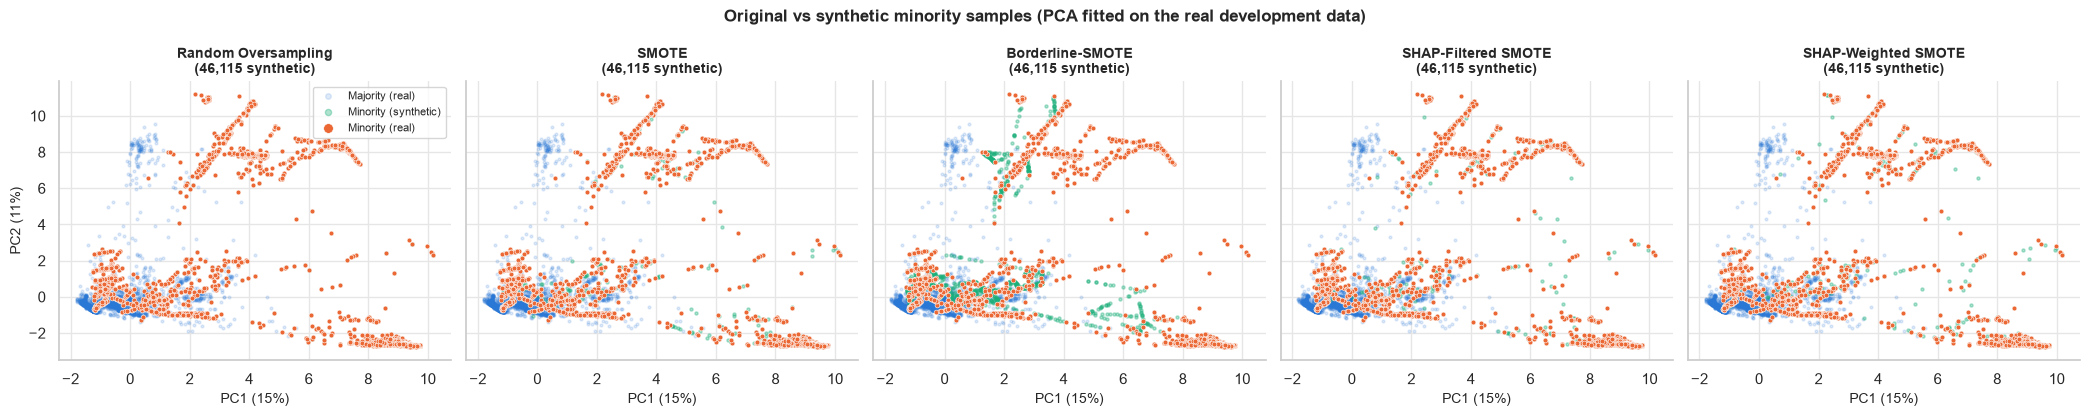

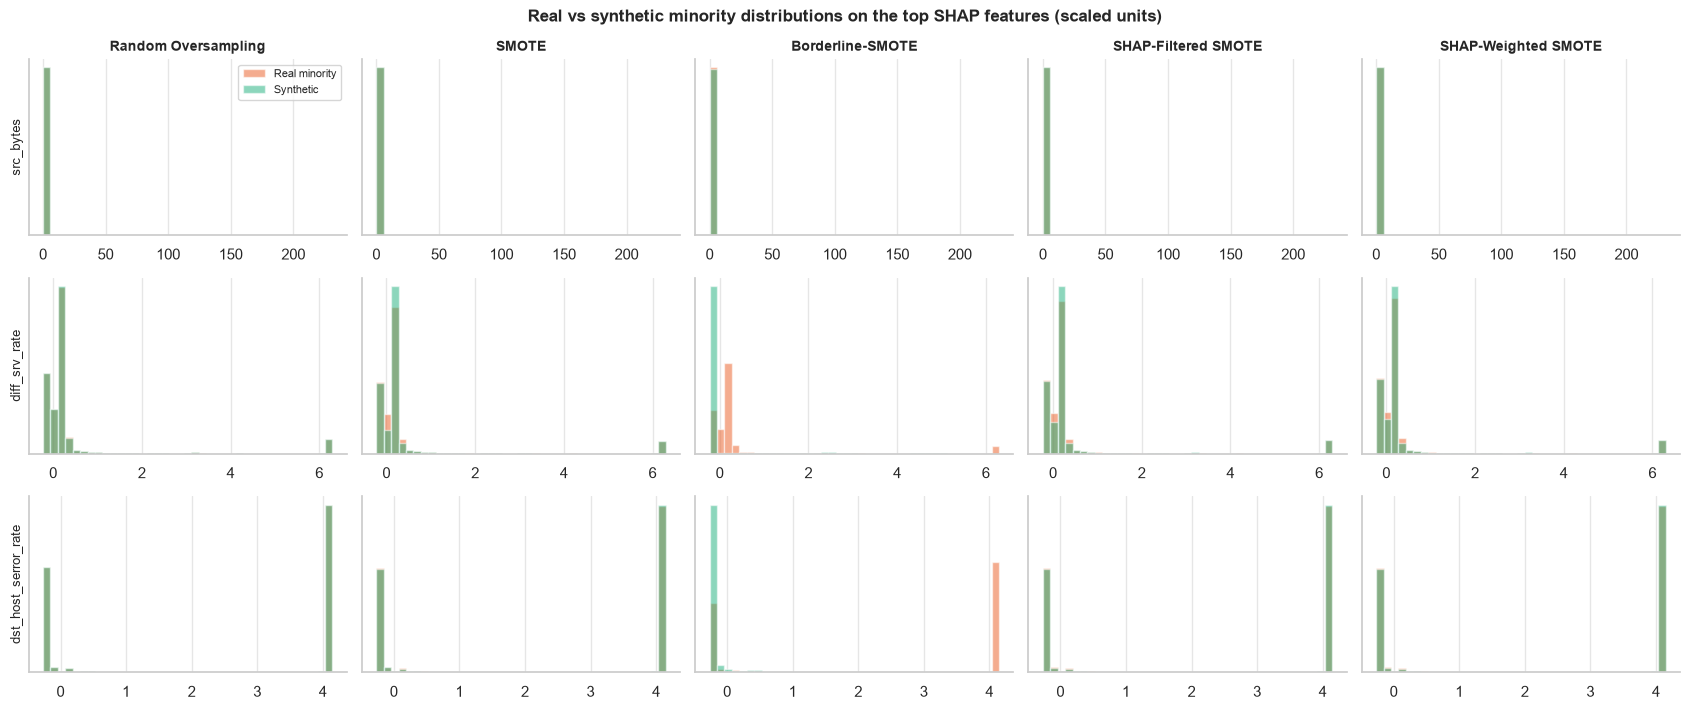

In [14]:
quality_tbl = I.synthetic_quality(final)
display(quality_tbl)
PL.pca_synthetic(final, PLOTS); plt.show()
PL.synthetic_feature_distributions(final, list(weights.index[:3]), PLOTS); plt.show()

In [15]:
files = O.save_sampling_artifacts(DIRS, final)
display(files)

,method,content,rows,file
0,Random Oversampling,synthetic samples,46115,results/nsl_kdd/synthetic_samples/random_overs...
1,SMOTE,synthetic samples,46115,results/nsl_kdd/synthetic_samples/smote_synthe...
2,SMOTE,neighbours,21960,results/nsl_kdd/neighbour_analysis/smote_neigh...
3,Borderline-SMOTE,synthetic samples,46115,results/nsl_kdd/synthetic_samples/borderline_s...
4,Borderline-SMOTE,neighbours,21960,results/nsl_kdd/neighbour_analysis/borderline_...
5,SHAP-Filtered SMOTE,synthetic samples,46115,results/nsl_kdd/synthetic_samples/shap_filtere...
6,SHAP-Filtered SMOTE,neighbours,21960,results/nsl_kdd/neighbour_analysis/shap_filter...
7,SHAP-Weighted SMOTE,synthetic samples,46115,results/nsl_kdd/synthetic_samples/shap_weighte...
8,SHAP-Weighted SMOTE,neighbours,21960,results/nsl_kdd/neighbour_analysis/shap_weight...
9,SHAP-Filtered SMOTE,"SHAP rationale (first 2,000 rows)",2000,results/nsl_kdd/neighbour_analysis/shap_filter...


## Stage 5: Repeated stratified cross-validation (leak-free)
For each of the 2 × 5 folds of the development set, the full chain (preprocessing → SHAP → oversampling → model) is
re-fitted on the training part with fresh objects, and scored on the untouched validation part. This gives a
mean ± standard deviation for every (method, model) pair, plus paired per-fold comparisons.

In [16]:
cv = R.run_cross_validation(dev_df, spec)
print(f"Cross-validation finished in {cv.elapsed_s / 60:.1f} min")

fold  1/10 done in  103.9 s


fold  2/10 done in  118.3 s


fold  3/10 done in  128.8 s


fold  4/10 done in  139.0 s


fold  5/10 done in  156.2 s


fold  6/10 done in  138.5 s


fold  7/10 done in  199.8 s


fold  8/10 done in  155.9 s


fold  9/10 done in  191.0 s


fold 10/10 done in  166.2 s
Cross-validation finished in 25.0 min


In [17]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: cross-validation, mean ± sd over {C.CV_SPLITS * C.CV_REPEATS} folds**"))
    display(S.cv_comparison_table(cv, model))

**Logistic Regression: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.993 ± 0.001,0.982 ± 0.004,0.928 ± 0.007,0.954 ± 0.005,0.993 ± 0.001,0.976 ± 0.003,0.999 ± 0.0
Random Oversampling,0.977 ± 0.002,0.795 ± 0.013,0.965 ± 0.006,0.872 ± 0.008,0.995 ± 0.001,0.976 ± 0.005,0.978 ± 0.002
SMOTE,0.978 ± 0.001,0.804 ± 0.012,0.965 ± 0.007,0.877 ± 0.007,0.995 ± 0.002,0.976 ± 0.005,0.98 ± 0.002
Borderline-SMOTE,0.963 ± 0.005,0.691 ± 0.028,0.965 ± 0.005,0.805 ± 0.02,0.99 ± 0.001,0.94 ± 0.009,0.962 ± 0.005
SHAP-Filtered SMOTE,0.978 ± 0.002,0.802 ± 0.013,0.965 ± 0.007,0.876 ± 0.008,0.995 ± 0.002,0.976 ± 0.004,0.979 ± 0.002
SHAP-Weighted SMOTE,0.978 ± 0.001,0.8 ± 0.012,0.965 ± 0.007,0.875 ± 0.007,0.995 ± 0.001,0.976 ± 0.004,0.979 ± 0.002


**Random Forest: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.992 ± 0.001,1.0 ± 0.0,0.898 ± 0.015,0.946 ± 0.008,0.999 ± 0.0,0.994 ± 0.002,1.0 ± 0.0
Random Oversampling,0.996 ± 0.001,0.976 ± 0.004,0.972 ± 0.007,0.974 ± 0.004,0.999 ± 0.0,0.995 ± 0.002,0.998 ± 0.0
SMOTE,0.995 ± 0.001,0.967 ± 0.011,0.97 ± 0.007,0.969 ± 0.006,0.999 ± 0.0,0.995 ± 0.002,0.997 ± 0.001
Borderline-SMOTE,0.977 ± 0.003,0.777 ± 0.024,0.992 ± 0.003,0.871 ± 0.015,0.999 ± 0.0,0.992 ± 0.002,0.975 ± 0.003
SHAP-Filtered SMOTE,0.996 ± 0.001,0.974 ± 0.01,0.97 ± 0.006,0.972 ± 0.006,0.999 ± 0.0,0.995 ± 0.002,0.998 ± 0.001
SHAP-Weighted SMOTE,0.995 ± 0.001,0.968 ± 0.017,0.971 ± 0.006,0.969 ± 0.009,0.999 ± 0.0,0.995 ± 0.002,0.997 ± 0.002


**XGBoost: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.999 ± 0.0,0.998 ± 0.003,0.988 ± 0.003,0.993 ± 0.001,1.0 ± 0.0,0.999 ± 0.001,1.0 ± 0.0
Random Oversampling,0.999 ± 0.0,0.99 ± 0.003,0.994 ± 0.002,0.992 ± 0.002,1.0 ± 0.0,0.999 ± 0.001,0.999 ± 0.0
SMOTE,0.999 ± 0.0,0.993 ± 0.003,0.99 ± 0.002,0.992 ± 0.002,1.0 ± 0.0,0.999 ± 0.001,0.999 ± 0.0
Borderline-SMOTE,0.998 ± 0.001,0.984 ± 0.004,0.99 ± 0.003,0.987 ± 0.003,1.0 ± 0.0,0.998 ± 0.001,0.999 ± 0.0
SHAP-Filtered SMOTE,0.999 ± 0.0,0.993 ± 0.003,0.991 ± 0.004,0.992 ± 0.002,1.0 ± 0.0,0.999 ± 0.001,0.999 ± 0.0
SHAP-Weighted SMOTE,0.999 ± 0.0,0.993 ± 0.004,0.992 ± 0.003,0.992 ± 0.002,1.0 ± 0.0,0.999 ± 0.001,0.999 ± 0.0


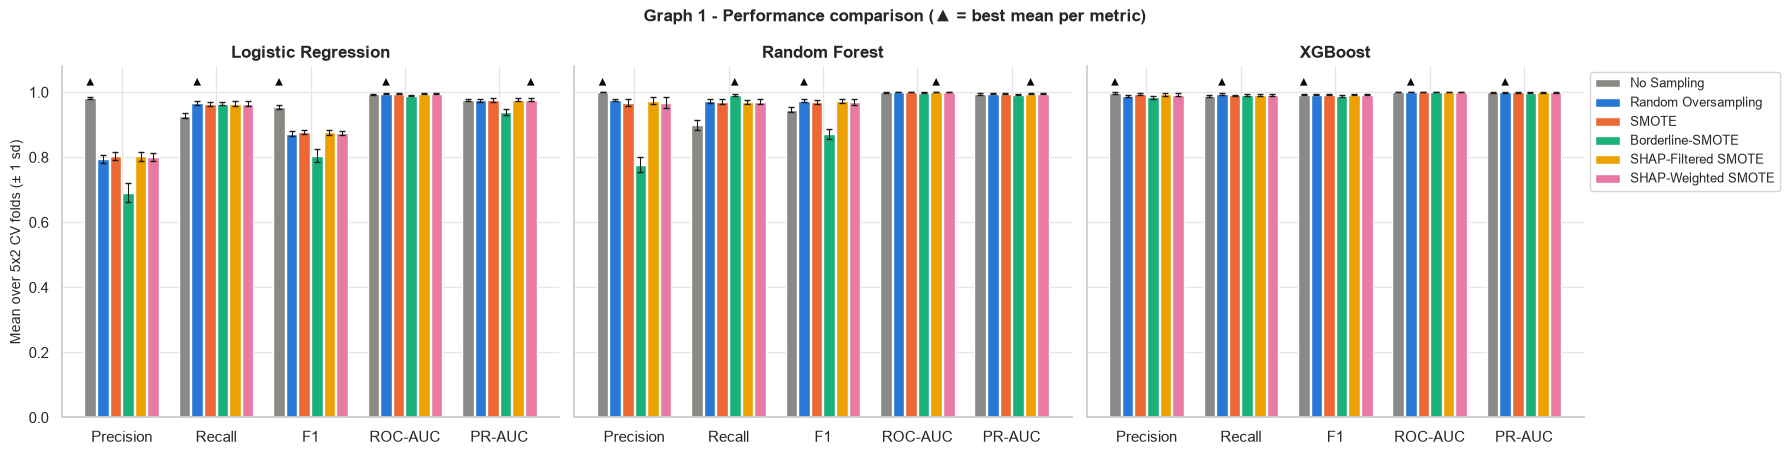

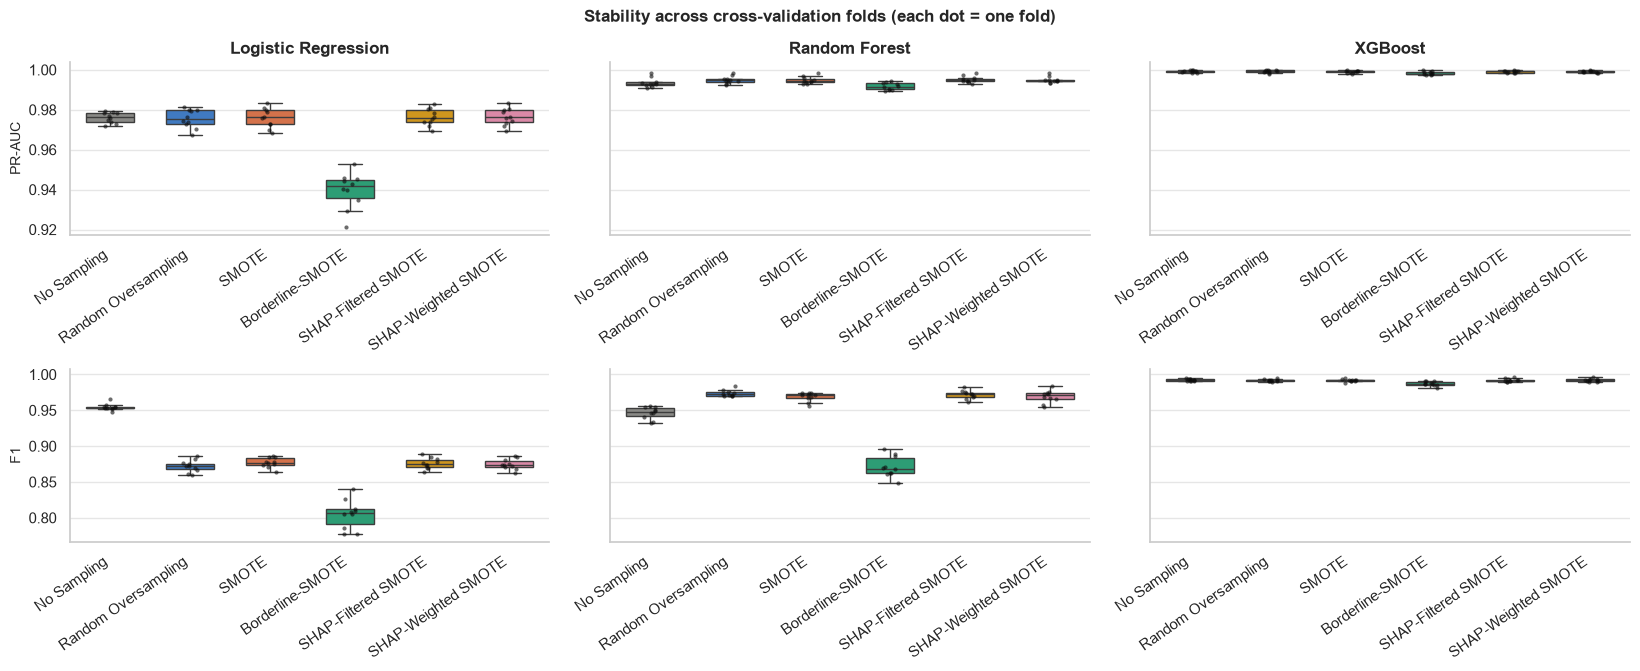

In [18]:
PL.performance_comparison(cv, PLOTS); plt.show()
PL.fold_distributions(cv, PLOTS); plt.show()

In [19]:
tests = R.paired_tests(cv)
display(Markdown("**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)"))
display(tests[tests.method.isin(C.PROPOSED_METHODS)].style.format({"mean_difference": "{:+.4f}", "p_value": "{:.3f}"})
        .apply(lambda r: ["font-weight: bold" if r.p_value < 0.05 else "" for _ in r], axis=1))

**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)

,model,method,vs,metric,mean_difference,folds_better,folds_worse,p_value
12,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,PR-AUC,+0.0003,7,3,0.322
13,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,F1,-0.0010,6,4,0.770
14,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Recall,+0.0003,6,2,0.664
15,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Precision,-0.0018,4,6,0.322
16,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,PR-AUC,+0.0005,7,3,0.105
17,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,F1,-0.0023,2,8,0.049
18,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Recall,+0.0000,3,5,0.867
19,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Precision,-0.0038,1,9,0.010
32,Random Forest,SHAP-Filtered SMOTE,SMOTE,PR-AUC,+0.0003,6,4,0.232
33,Random Forest,SHAP-Filtered SMOTE,SMOTE,F1,+0.0033,8,2,0.193


## Stage 6: Hold-out test evaluation
The models fitted in Stage 4 on the (resampled) development set are scored **once** on the untouched 25% test
set, at the 0.5 decision threshold. Test-set rankings rest on a single split and few minority cases, so read them
together with the cross-validation results in Stage 5.

In [20]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: hold-out test set**"))
    display(S.comparison_table(final, model).style.format("{:.4f}").highlight_max(axis=0, props="font-weight: bold"))
cm = final.test_metrics.set_index(["model", "method"])[["tn", "fp", "fn", "tp", "brier", "ece"]]
display(Markdown("**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**"))
display(cm)

**Logistic Regression: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9938,0.9856,0.9365,0.9604,0.9940,0.9801,0.9988
Random Oversampling,0.9775,0.7932,0.9720,0.8735,0.9948,0.9792,0.9780
SMOTE,0.9780,0.7970,0.9734,0.8764,0.9946,0.9801,0.9784
Borderline-SMOTE,0.9573,0.6574,0.9727,0.7846,0.9900,0.9359,0.9559
SHAP-Filtered SMOTE,0.9783,0.7989,0.9740,0.8778,0.9947,0.9803,0.9787
SHAP-Weighted SMOTE,0.9774,0.7918,0.9740,0.8735,0.9946,0.9800,0.9777


**Random Forest: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9936,1.0000,0.9194,0.9580,0.9990,0.9935,1.0000
Random Oversampling,0.9966,0.9882,0.9686,0.9783,0.9994,0.9958,0.9990
SMOTE,0.9964,0.9875,0.9679,0.9776,0.9994,0.9955,0.9989
Borderline-SMOTE,0.9749,0.7649,0.9911,0.8634,0.9989,0.9921,0.9735
SHAP-Filtered SMOTE,0.9945,0.9627,0.9693,0.9660,0.9992,0.9952,0.9967
SHAP-Weighted SMOTE,0.9953,0.9719,0.9693,0.9706,0.9992,0.9948,0.9976


**XGBoost: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9991,0.9986,0.9898,0.9942,0.9998,0.9989,0.9999
Random Oversampling,0.9989,0.9932,0.9932,0.9932,0.9997,0.9986,0.9994
SMOTE,0.9988,0.9932,0.9918,0.9925,0.9998,0.9988,0.9994
Borderline-SMOTE,0.9974,0.9752,0.9925,0.9838,0.9996,0.9976,0.9978
SHAP-Filtered SMOTE,0.9989,0.9938,0.9918,0.9928,0.9998,0.9988,0.9995
SHAP-Weighted SMOTE,0.9990,0.9952,0.9918,0.9935,0.9998,0.9987,0.9996


**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**

,,tn,fp,fn,tp,brier,ece
model,method,,,,,,
Logistic Regression,No Sampling,16816,20,93,1371,0.0059,0.0031
Random Forest,No Sampling,16836,0,118,1346,0.0058,0.0156
XGBoost,No Sampling,16834,2,15,1449,0.0009,0.0010
Logistic Regression,Random Oversampling,16465,371,41,1423,0.0162,0.0346
Random Forest,Random Oversampling,16819,17,46,1418,0.0096,0.0558
XGBoost,Random Oversampling,16826,10,10,1454,0.0011,0.0032
Logistic Regression,SMOTE,16473,363,39,1425,0.0166,0.0331
Random Forest,SMOTE,16818,18,47,1417,0.0090,0.0556
XGBoost,SMOTE,16826,10,12,1452,0.0011,0.0028


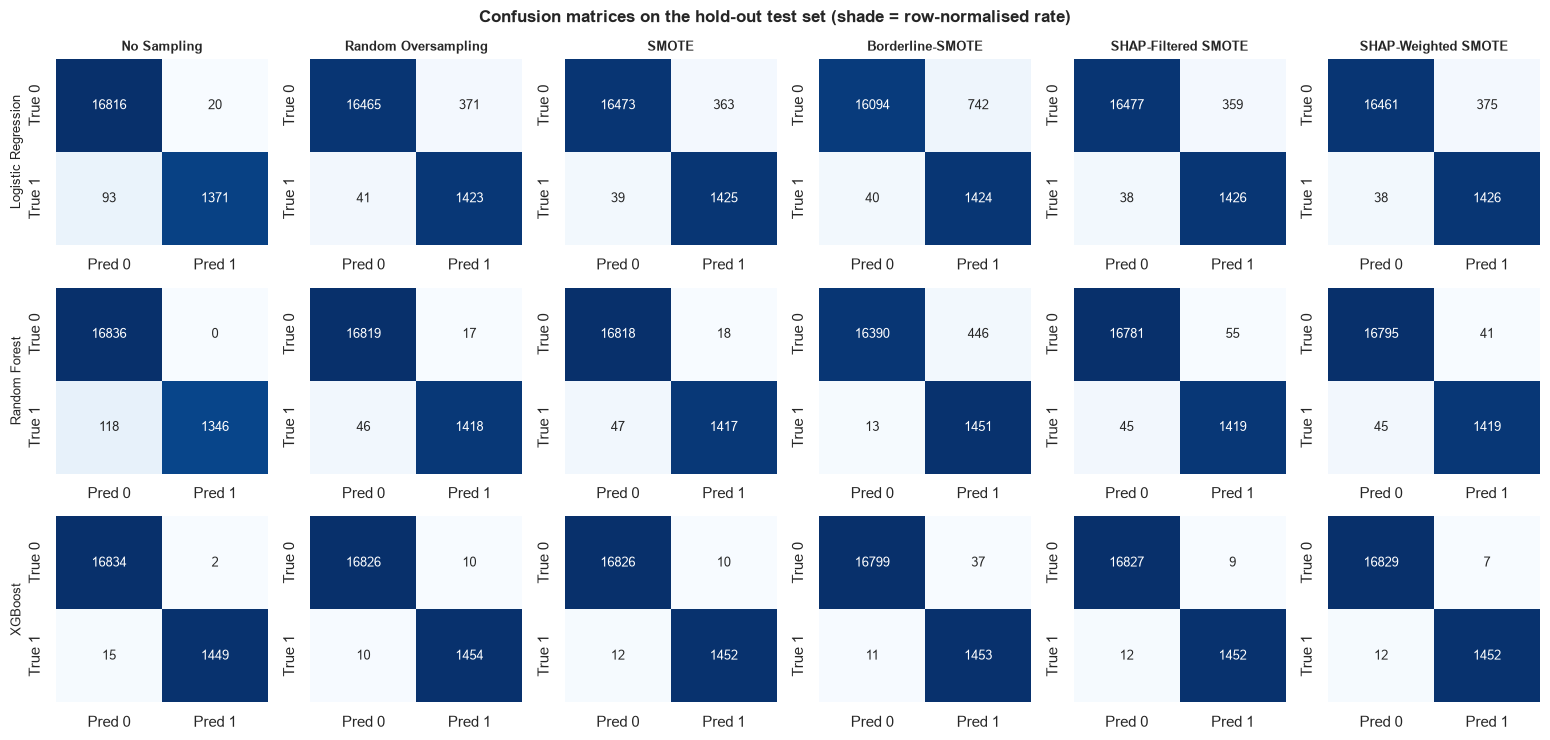

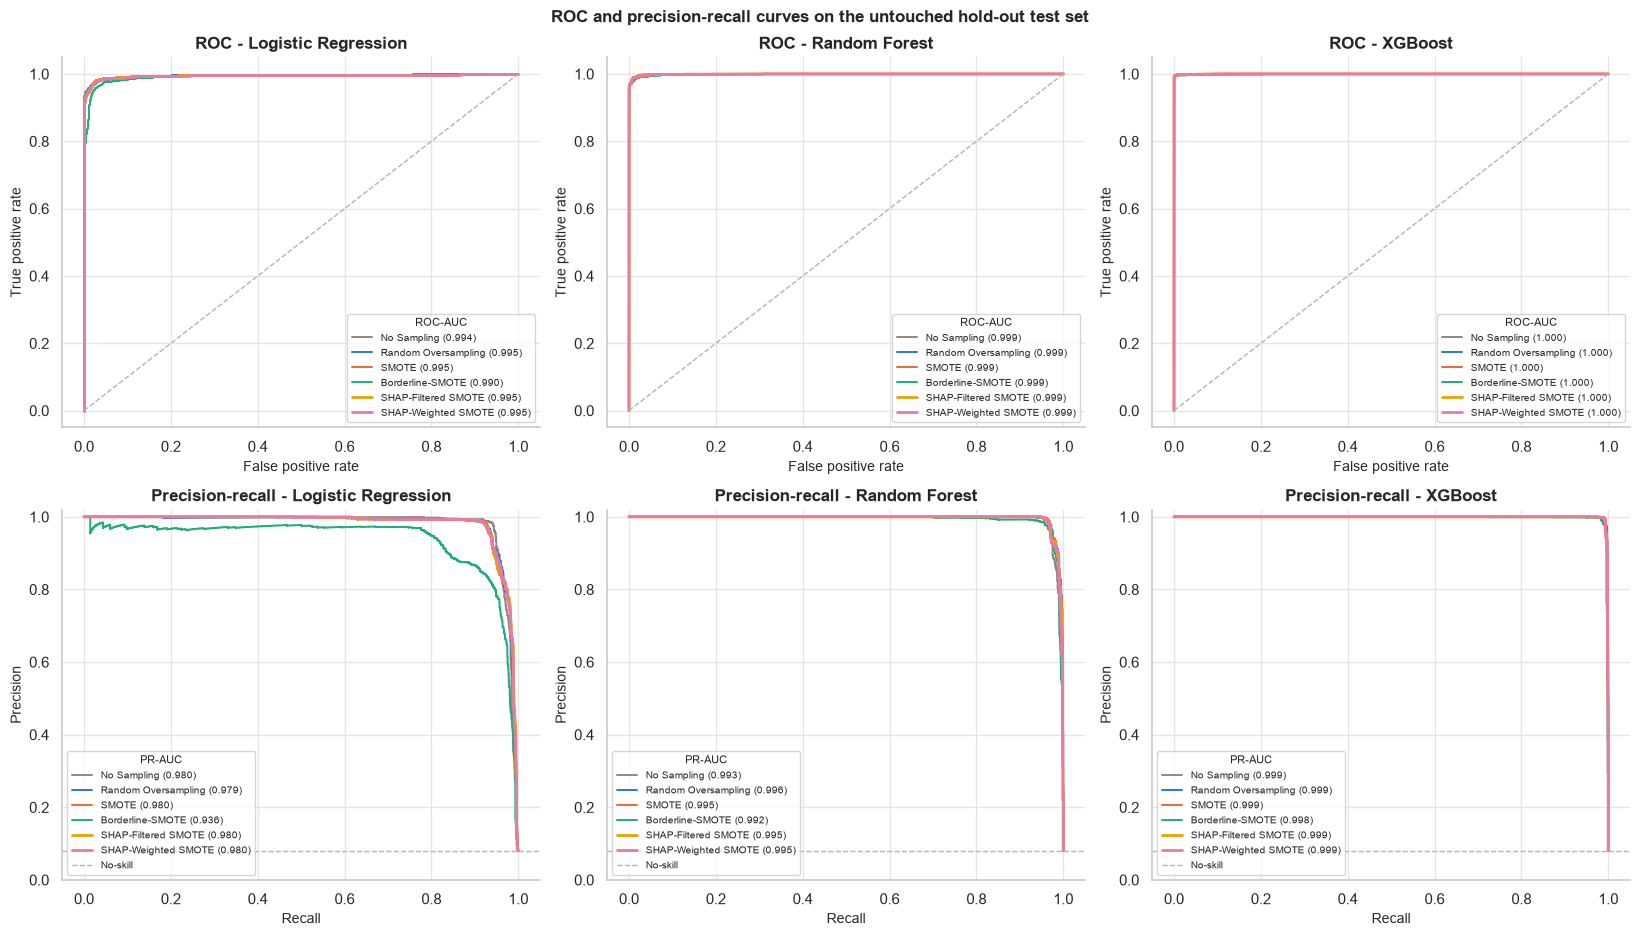

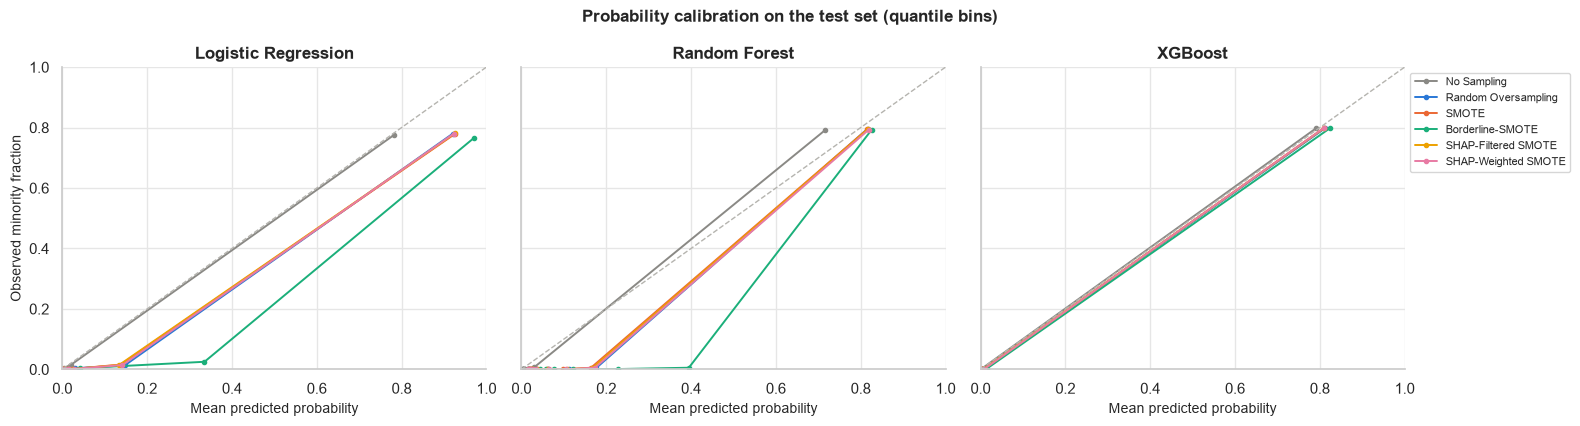

In [21]:
PL.confusion_matrices(final, PLOTS); plt.show()
PL.roc_pr_curves(final, PLOTS); plt.show()
PL.calibration_curves(final, PLOTS); plt.show()

## Stage 7: SHAP explainability comparison
Do the final models rely on different features depending on how their training data was balanced? Each final
model is explained on the same test rows (all minority rows up to 250, plus majority rows up to 500 in total).
Logistic Regression uses `LinearExplainer` with a training background; the tree models use `TreeExplainer`.
Across CV folds, the stability of each model's SHAP feature ranking is measured with Kendall τ.

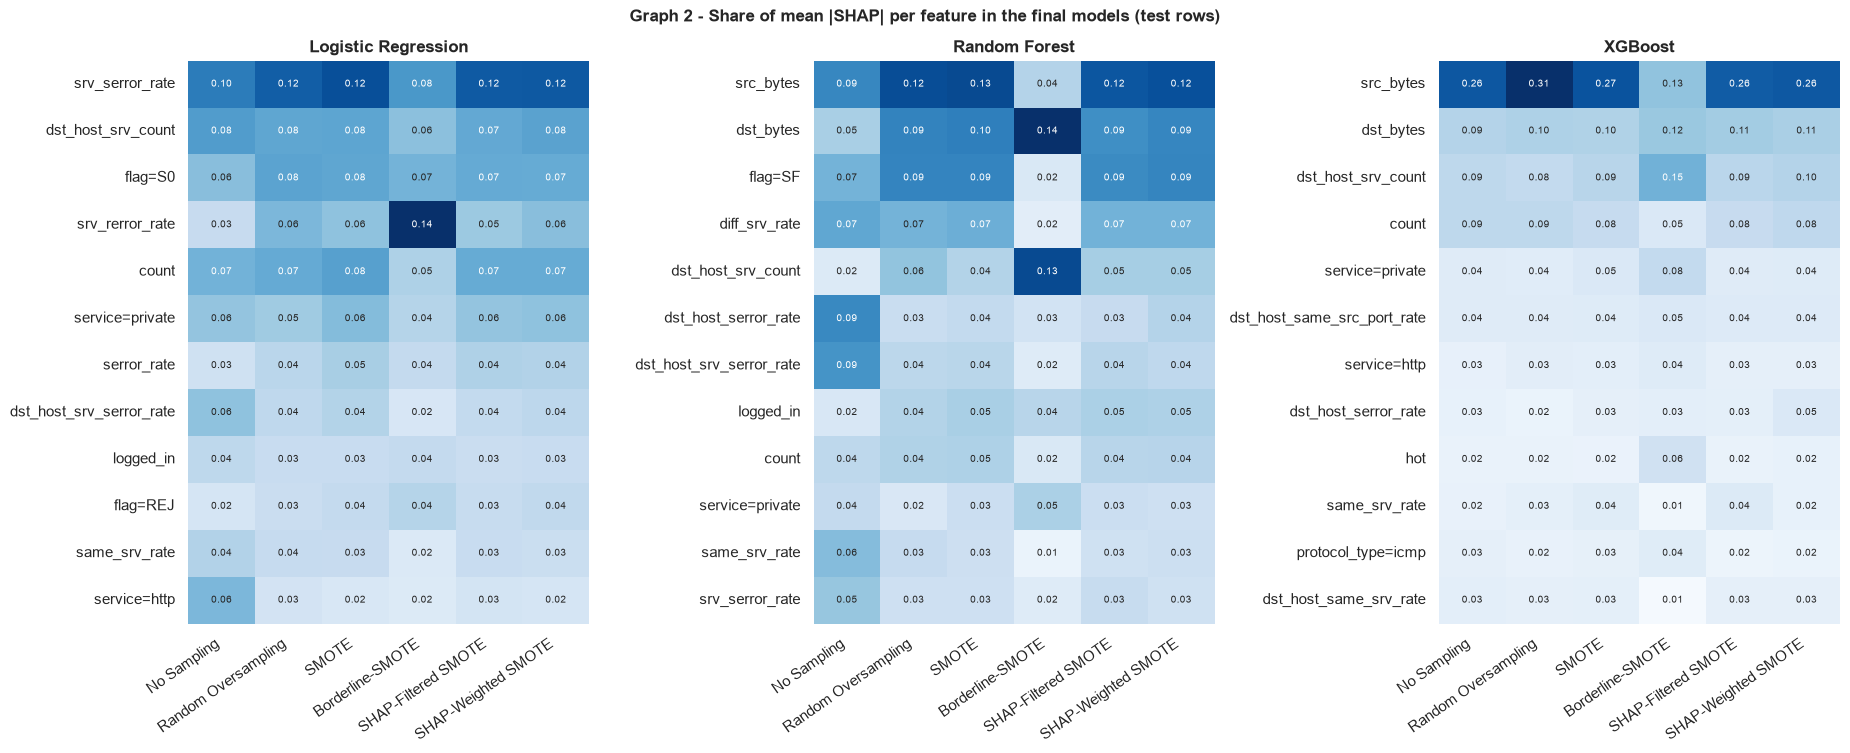

**Spearman correlation of each final model's feature-importance vector with the No Sampling model**

,Logistic Regression,Random Forest,XGBoost
No Sampling,1.0000,1.0000,1.0000
Random Oversampling,0.8859,0.8943,0.9292
SMOTE,0.8446,0.8919,0.9532
Borderline-SMOTE,0.8446,0.8486,0.9297
SHAP-Filtered SMOTE,0.8496,0.8973,0.9500
SHAP-Weighted SMOTE,0.8321,0.8639,0.9503


In [22]:
PL.shap_explainability_comparison(final, PLOTS); plt.show()
rank_corr = pd.DataFrame({model: final.importance_table(model).T.corr(method="spearman")["No Sampling"]
                          for model in C.MODEL_ORDER})
display(Markdown("**Spearman correlation of each final model's feature-importance vector with the No Sampling model**"))
display(rank_corr)

,,kendall_tau_mean,kendall_tau_std,spearman_rho_mean,spearman_rho_std,top_k_overlap
model,method,,,,,
Logistic Regression,No Sampling,0.7330,0.0307,0.8665,0.0267,0.6942
Random Forest,No Sampling,0.7822,0.0219,0.9067,0.0159,0.8444
XGBoost,No Sampling,0.9270,0.0135,0.9703,0.0105,1.0000
Logistic Regression,Random Oversampling,0.7439,0.0344,0.8771,0.0290,0.9333
Random Forest,Random Oversampling,0.8285,0.0219,0.9256,0.0154,0.8444
XGBoost,Random Oversampling,0.9154,0.0141,0.9732,0.0080,0.7852
Logistic Regression,SMOTE,0.7394,0.0291,0.8748,0.0242,0.8444
Random Forest,SMOTE,0.8265,0.0202,0.9277,0.0134,0.8148
XGBoost,SMOTE,0.9202,0.0152,0.9732,0.0097,0.8741


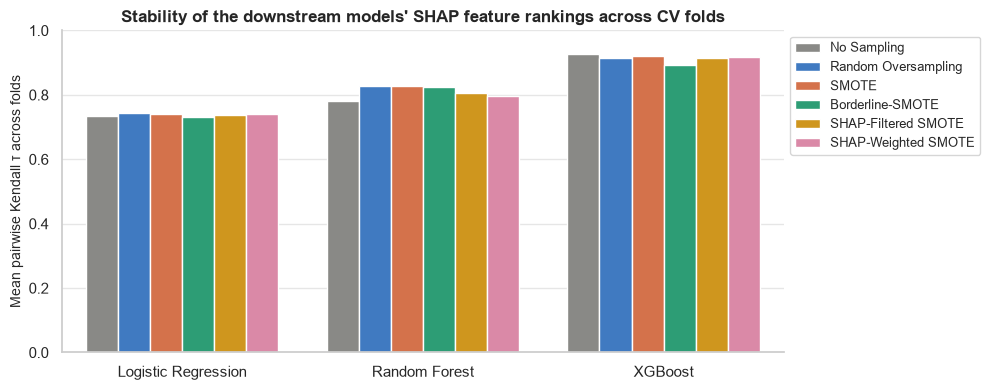

In [23]:
stability = R.attribution_stability(cv)
display(stability)
PL.attribution_stability_plot(stability, PLOTS); plt.show()

## Stage 8: Saved outputs and summary
Every table and figure is saved under `results/<dataset>/` (same layout for all datasets):
`metrics/`, `synthetic_samples/`, `neighbour_analysis/` and `plots/`.

In [24]:
saved = O.save_metrics(DIRS, dev_df, test_df, cv, final, stability, tests, quality_tbl)
display(saved)
print("plots:", ", ".join(sorted(p.name for p in PLOTS.glob("*.png"))))

,file
0,results/nsl_kdd/metrics/split_assignment.csv.gz
1,results/nsl_kdd/metrics/cv_fold_metrics.csv
2,results/nsl_kdd/metrics/cv_mean_metrics.csv
3,results/nsl_kdd/metrics/cv_summary_mean_sd.csv
4,results/nsl_kdd/metrics/cv_sampling_runtime.csv
5,results/nsl_kdd/metrics/test_metrics.csv
6,results/nsl_kdd/metrics/final_sampling_counts.csv
7,results/nsl_kdd/metrics/attribution_stability.csv
8,results/nsl_kdd/metrics/paired_tests_vs_smote.csv
9,results/nsl_kdd/metrics/synthetic_quality.csv


plots: 01_class_distribution.png, 02_feature_distributions.png, 03_correlation_heatmap.png, 04_class_comparison.png, 05_balanced_class_counts.png, 06_shap_feature_weights.png, 07_shap_summary_preliminary_model.png, 08_pca_original_vs_synthetic.png, 09_synthetic_feature_distributions.png, 10_graph1_performance_comparison.png, 11_cv_fold_stability.png, 12_roc_pr_curves.png, 13_confusion_matrices.png, 14_calibration_curves.png, 15_graph2_shap_explainability_comparison.png, 16_attribution_stability.png


### Final summary
Numbers below are computed from this run, not typed by hand.

In [25]:
display(Markdown(f"**Dataset:** {spec.title}, {len(df):,} rows, {len(spec.features)} raw features "
                 f"({len(pre.feature_names_)} model columns after encoding)."))
display(D.overview(df, spec))
display(Markdown("**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, "
                 "one-hot encoding and standard scaling fitted on training rows only; oversampling only inside "
                 "training folds."))
display(Markdown("**Oversampling results (final development-set fit):**"))
display(final.sampling.join(quality_tbl.reindex(columns=["majority_share_in_5nn", "mean_wasserstein_distance",
                                          "correlation_matrix_similarity", "detectability_auc_all", "detectability_auc_numeric"]), how="left"))
display(Markdown("**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**"))
display(S.dataset_findings(cv, tests, quality_tbl).T)
display(Markdown("**Findings derived from the numbers:**\n" + "\n".join(f"- {l}" for l in S.findings_text(cv, tests, quality_tbl))))

**Dataset:** NSL-KDD Network Intrusion (KDDTrain+), 73,199 rows, 40 raw features (116 model columns after encoding).

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
NSL-KDD Network Intrusion (KDDTrain+),Network security,73199,37,3,67343,5856,8.00%,11.5 : 1,1 : 11.5


**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, one-hot encoding and standard scaling fitted on training rows only; oversampling only inside training folds.

**Oversampling results (final development-set fit):**

,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds,majority_share_in_5nn,mean_wasserstein_distance,correlation_matrix_similarity,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,
No Sampling,50507,4392,0,50507,4392,0.0440,NaN,NaN,NaN,NaN,NaN
Random Oversampling,50507,4392,46115,50507,50507,1.4074,0.0159,0.0023,0.9007,NaN,NaN
SMOTE,50507,4392,46115,50507,50507,2.6975,0.0124,0.0031,0.9013,0.8660,0.8881
Borderline-SMOTE,50507,4392,46115,50507,50507,4.0282,0.3170,0.2612,0.4441,0.9704,0.9704
SHAP-Filtered SMOTE,50507,4392,46115,50507,50507,21.9148,0.0146,0.0049,0.9010,0.8840,0.8526
SHAP-Weighted SMOTE,50507,4392,46115,50507,50507,15.6802,0.0127,0.0047,0.9007,0.8814,0.8556


**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**

model,Logistic Regression,Random Forest,XGBoost
best PR-AUC,SHAP-Weighted SMOTE (0.976),SHAP-Filtered SMOTE (0.995),Random Oversampling (0.999)
best F1,No Sampling (0.954),Random Oversampling (0.974),No Sampling (0.993)
best recall,Random Oversampling (0.965),Borderline-SMOTE (0.992),Random Oversampling (0.994)
SHAP-F - SMOTE PR-AUC,+0.000 (p=0.32),+0.000 (p=0.23),-0.000 (p=0.38)
SHAP-F - SMOTE F1,-0.001 (p=0.77),+0.003 (p=0.19),+0.000 (p=0.56)
SHAP-F - SMOTE Recall,+0.000 (p=0.66),-0.000 (p=0.84),+0.001 (p=0.30)
SHAP-F - SMOTE Precision,-0.002 (p=0.32),+0.007 (p=0.16),-0.000 (p=0.56)
SHAP-W - SMOTE PR-AUC,+0.000 (p=0.11),+0.000 (p=0.28),-0.000 (p=0.77)
SHAP-W - SMOTE F1,-0.002 (p=0.05),+0.001 (p=1.00),+0.000 (p=0.11)
SHAP-W - SMOTE Recall,+0.000 (p=0.87),+0.001 (p=0.38),+0.001 (p=0.02)


**Findings derived from the numbers:**
- Logistic Regression: PR-AUC ranking = SHAP-Weighted SMOTE 0.976 > SHAP-Filtered SMOTE 0.976 > No Sampling 0.976 > SMOTE 0.976 > Random Oversampling 0.976 > Borderline-SMOTE 0.940
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.000 (7/10 folds better, p=0.322, not significant); F1 -0.001 (6/10 folds better, p=0.770, not significant); Recall +0.000 (6/8 folds better, p=0.664, not significant); Precision -0.002 (4/10 folds better, p=0.322, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.000 (7/10 folds better, p=0.105, not significant); F1 -0.002 (2/10 folds better, p=0.049, significant); Recall +0.000 (3/8 folds better, p=0.867, not significant); Precision -0.004 (1/10 folds better, p=0.010, significant)
- Random Forest: PR-AUC ranking = SHAP-Filtered SMOTE 0.995 > SHAP-Weighted SMOTE 0.995 > Random Oversampling 0.995 > SMOTE 0.995 > No Sampling 0.994 > Borderline-SMOTE 0.992
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.000 (6/10 folds better, p=0.232, not significant); F1 +0.003 (8/10 folds better, p=0.193, not significant); Recall -0.000 (5/10 folds better, p=0.844, not significant); Precision +0.007 (8/10 folds better, p=0.160, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.000 (6/10 folds better, p=0.275, not significant); F1 +0.001 (5/10 folds better, p=1.000, not significant); Recall +0.001 (4/5 folds better, p=0.375, not significant); Precision +0.001 (5/10 folds better, p=1.000, not significant)
- XGBoost: PR-AUC ranking = Random Oversampling 0.999 > No Sampling 0.999 > SMOTE 0.999 > SHAP-Weighted SMOTE 0.999 > SHAP-Filtered SMOTE 0.999 > Borderline-SMOTE 0.998
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC -0.000 (3/10 folds better, p=0.375, not significant); F1 +0.000 (6/10 folds better, p=0.557, not significant); Recall +0.001 (5/8 folds better, p=0.297, not significant); Precision -0.000 (4/10 folds better, p=0.557, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC -0.000 (5/10 folds better, p=0.770, not significant); F1 +0.000 (7/10 folds better, p=0.105, not significant); Recall +0.001 (7/8 folds better, p=0.016, significant); Precision -0.001 (4/10 folds better, p=0.625, not significant)
- Synthetic rows' majority share among 5 nearest real rows (lower = less overlap): Real minority (reference) 0.021, Random Oversampling 0.016, SMOTE 0.012, Borderline-SMOTE 0.317, SHAP-Filtered SMOTE 0.015, SHAP-Weighted SMOTE 0.013
- Mean marginal Wasserstein distance synthetic vs real minority (lower = closer): Random Oversampling 0.002, SMOTE 0.003, Borderline-SMOTE 0.261, SHAP-Filtered SMOTE 0.005, SHAP-Weighted SMOTE 0.005
- Correlation-structure similarity synthetic vs real minority (1 = identical): Random Oversampling 0.901, SMOTE 0.901, Borderline-SMOTE 0.444, SHAP-Filtered SMOTE 0.901, SHAP-Weighted SMOTE 0.901
- Real-vs-synthetic detectability AUC, all columns / numeric only (0.5 = indistinguishable): SMOTE 0.866 / 0.888, Borderline-SMOTE 0.970 / 0.970, SHAP-Filtered SMOTE 0.884 / 0.853, SHAP-Weighted SMOTE 0.881 / 0.856

### Interpretation: NSL-KDD network intrusion (11.5 : 1)

**Which method performed best?** **No Sampling with XGBoost**: CV F1 0.993, PR-AUC 0.999, precision 0.998. The
task is close to saturated for gradient boosting: Random Oversampling, SMOTE and both SHAP methods with XGBoost are
within 0.001 of it on PR-AUC. Oversampling matters for the other two models, but in opposite directions:
* **Random Forest:** oversampling raises recall from 0.90 to about 0.97 and F1 from 0.946 to 0.969–0.974.
  Random Oversampling is best (F1 0.974) and SHAP-Filtered SMOTE second (0.972).
* **Logistic Regression:** oversampling raises recall from 0.93 to 0.96 but drops precision from 0.98 to about
  0.80, so F1 falls from 0.954 to about 0.875 for every oversampler.

**Did SHAP-guided SMOTE improve minority-class detection?** Not in any practical sense. Recall differences from
SMOTE are at most ±0.002. The one significant gain is SHAP-Weighted SMOTE with XGBoost (+0.0015 recall, better in
7 of 8 folds that differ, p = 0.016), a fraction of one attack per validation fold.

**PR-AUC and F1?** PR-AUC differences from SMOTE are below 0.001 everywhere (none significant). F1: SHAP-Filtered
SMOTE with Random Forest is the largest gain (+0.003, 8 of 10 folds, p = 0.19, not significant). SHAP-Weighted
SMOTE with Logistic Regression is significantly *worse* (−0.002, p = 0.049).

**Precision?** Unchanged to slightly lower. SHAP-Weighted SMOTE with Logistic Regression loses 0.004 (worse in 9 of
10 folds, p = 0.010). SHAP-Filtered SMOTE with Random Forest gains 0.007 in CV (not significant), but on the
single hold-out split it produced *more* false positives than SMOTE (55 vs 18).

**Did the synthetic samples preserve feature relationships?** SMOTE and the two SHAP methods produce statistically
similar samples: 95% of features pass the KS test, correlation-structure similarity is 0.90 (the same as random
oversampling), and only 1.2–1.5% majority rows sit among their 5 nearest real neighbours (the real attacks: 2.1%).
All three are fairly easy to tell from real attacks (detectability AUC 0.87–0.88). This is driven by the heavy-tailed
count and byte features, where interpolation creates values no real record has. On the numeric columns alone the
SHAP methods are slightly *more* realistic (0.85–0.86 vs 0.89). SHAP guidance changes about half of every seed's
neighbours (mean Jaccard 0.50–0.51 with SMOTE's), and paired parents already have very similar explanations under
every method (SHAP cosine 0.98). SHAP-Filtered SMOTE searches on 23 of 116 columns.

As on Stroke, SHAP pairing leaves far more fractional category indicators (0.84–0.92 per synthetic row vs 0.13 for
SMOTE: SHAP down-weights protocol/service/flag mismatches). Here it does not hurt the tree models, because
the attack signal in the numeric traffic features is strong and the minority class is large (about 3,500
attacks per training fold).

**Borderline-SMOTE** is clearly the worst method on this dataset. Its synthetic rows sit in normal-traffic territory
(32% majority neighbours), break the correlation structure (similarity 0.44), are almost perfectly detectable
(AUC 0.97), and cut Random Forest precision to 0.78.

**Where did SHAP-guided SMOTE fail or underperform?** It did not fail, but it had nothing to add. SHAP rewired half
of the neighbour graph and the downstream models barely noticed, because SMOTE's neighbours are already
in a dense, well-separated minority region. Its oversampling step is also about 5× slower than SMOTE's
(9–11 s vs 1.8 s per fold, mostly the preliminary model and SHAP).